# 12 线性回归模型的正则化

> **模块**：回归分析 ｜ **数据**：`regularization.csv` ｜ **依赖**：pandas、scikit-learn

## 1. 问题背景

在处理较为复杂的数据的回归问题时，普通的线性回归算法通常会出现预测精度不够的问题。如果模型中的特征之间有相关关系，就会增加模型的复杂程度。当数据集中的特征之间有较强的线性相关性时，即特征之间出现严重的多重共线性时，用普通最小二乘法估计模型参数，往往参数估计的方差太大，此时，求解出来的模型就很不稳定。

对于数据存在多重共线性和模型过拟合问题，可以选择在损失函数中加上正则项方法来改善，本次实验介绍基于不同正则项的两种正则化线性模型：岭回归和 LASSO 回归。


## 2. 学习目标

- 掌握岭回归的思路和基本方法
- 掌握 LASSO 回归的思路和基本方法


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 过拟合和正则化

#### 4.1.1 过拟合

所谓过拟合（over-fitting）其实就是所建的机器学习模型或者是深度学习模型在训练样本中表现得过于优越，导致在验证数据集以及测试数据集中表现不佳。

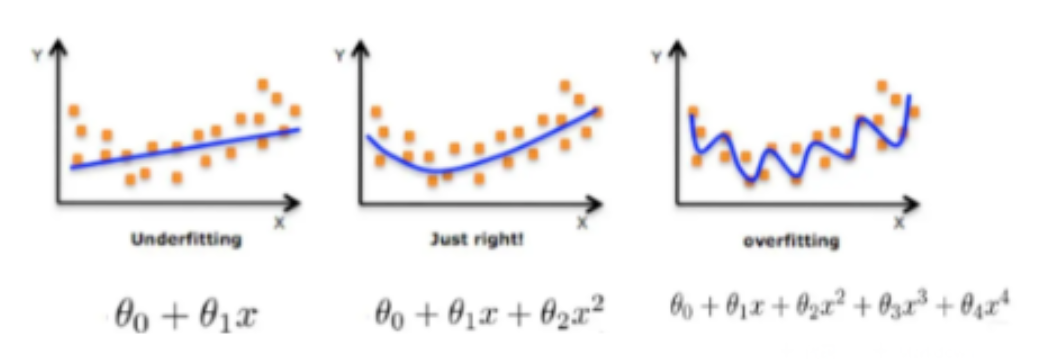

造成过拟合的本质原因是模型学习得太过精密，导致连训练集中的样本噪声都训练进入了模型。

所谓欠拟合（under-fitting）与过拟合恰好相反，模型学习得太过粗糙，连训练集中的样本数据特征关系（数据分布）都没有学出来。

解决过拟合的方法主要有以下几种：

**数据层面**：
- 数据集扩增（Data augmentation），获取更多的数据。
- 特征工程，筛选组合得到更高质量的特征。

**模型层面**：
- 选择较为简单的模型。
- 集成学习，Bagging 策略组合模型降低模型方差。
- 加入正则项，如 L1、L2 正则项，以及树模型的剪枝策略。

#### 4.1.2 范数

范数，在机器学习中通常用于衡量一个向量的大小，范数的定义如下：

$$L^p= {|x|}_p =  {(\sum_{i}{{|x_i|}^p})}^{\frac{1}{p}} \quad (p \geq 1)$$

比较常见的范数如下：
- L1 范数：${||x||}_1 = \sum_{i}{|x_i|} = |x_1| + |x_2| + \ldots + |x_n$（各个元素绝对值之和）
- L2 范数：${||x||}_2 = {[\sum_{i}{{x_i}^2}]}^{\frac{1}{2}} = \sqrt{{x_1}^2 + {x_2}^2 + \ldots + {x_n}^2}$（各个元素平方和的平方根）

#### 4.1.3 正则化

正则化就是通过对模型参数进行调整（数量和大小），降低模型的复杂度，以达到可以避免过拟合的效果。正则化是机器学习中的一种叫法，其它领域内叫法各不相同：

**机器学习把 L1 和 L2 叫正则化，统计学领域叫惩罚项，数学领域叫范数。**

正则化是一种常见的防止过拟合的方法，一般原理是在代价函数后面加上一个对参数的约束项，这个约束项被叫做正则化项（regularizer）。在线性回归模型中，通常有两种不同的正则化项：
- 加上所有参数（不包括 $β_0$）的绝对值之和，即 L1 范数，此时叫做 Lasso 回归。
- 加上所有参数（不包括 $β_0$）的平方和，即 L2 范数，此时叫做岭回归。

### 4.2 岭回归

#### 4.2.1 岭回归原理

对于多元线性回归模型 $Y = Xβ + ε$，参数方程的解为：

$$\hat{β} = {(X^TX)^{-1}X^TY}$$

其中：

$$
Y =
\begin{bmatrix}
y_1 \\
y_2 \\
\vdots \\
y_n
\end{bmatrix}, \quad
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \ldots & x_{1p} \\
1 & x_{21} & x_{22} & \ldots & x_{2p} \\
\vdots & \vdots & \vdots & & \vdots \\
1 & x_{n1} & x_{n2} & \ldots & x_{np}
\end{bmatrix}, \quad
β =
\begin{bmatrix}
β_0 \\
β_1 \\
\vdots \\
β_p
\end{bmatrix}, \quad
ε =
\begin{bmatrix}
ε_1 \\
ε_2 \\
\vdots \\
ε_n
\end{bmatrix}

$$

多元线性回归模型的目标函数：

$$J(β) = \sum{{(Y - Xβ)}^2}$$

为了保证回归系数 $β$ 可求（若 $X^TX$ 不是满秩矩阵且 $|X^TX| \approx 0$），岭回归模型在目标函数上加了一个 L2 范数的惩罚项：

$$J(β) = \sum{{(Y - Xβ)}^2} + λ{||β||}_2 = \sum{{(Y - Xβ)}^2} + \sum{λβ^2}$$

其中 $λ$ 表示正则化参数，$λ$ 为非负数。
- 当 $λ$ 过大时，为了使 $J(β)$ 最小，回归系数 $β$ 就越小，造成欠拟合。
- 当 $λ$ 过小时，会导致对拟合问题解决不当。

此时：

$$\hat{β} = {(X^TX + λI)^{-1}X^TY}$$

L2 范数惩罚项的加入使得 $(X^TX + λI)$ 矩阵满秩，保证了可逆，但是由于惩罚项的加入，使得回归系数 $β$ 的估计不再是无偏估计。因此，岭回归是以放弃无偏性、降低精度为代价解决病态矩阵问题的回归方法。

**单位矩阵 $I$ 的对角线上全是 1，像一条山岭一样，这也是岭回归名称的由来。**

**例1**：海天味业，中国专业的调味品生产企业，其主营产品包括酱油、耗油、酱类以及其他，根据这四类产品的线上销售，利用多元线性回归模型对公司的营业收入进行预测。具体如下表：

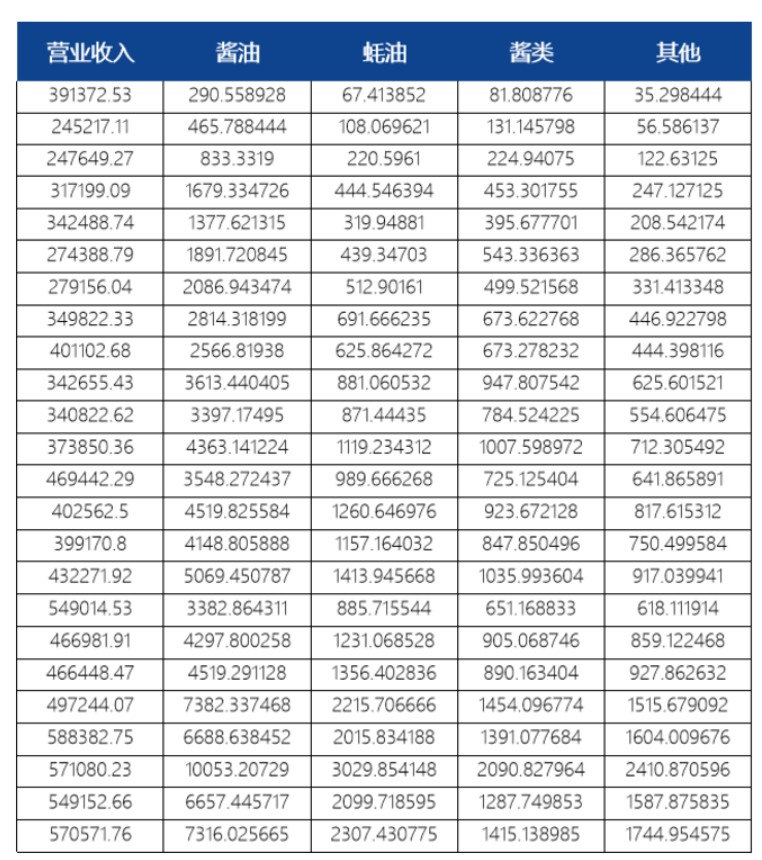

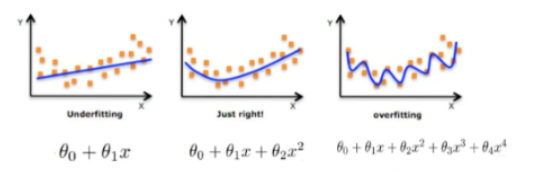

In [7]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from sklearn.linear_model import Ridge, RidgeCV,Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
plt.rc('font',family="SimHei")
plt.rc('axes',unicode_minus=False)
warnings.filterwarnings('always')
warnings.filterwarnings('ignore')
df = pd.read_csv("../data/regularization.csv")
df = df[['酱油','蚝油','酱类','其他','营业收入']]
df

,酱油,蚝油,酱类,其他,营业收入
0,290.558928,67.413852,81.808776,35.298444,391372.53
1,465.788444,108.069621,131.145798,56.586137,245217.11
2,833.331900,220.596100,224.940750,122.631250,247649.27
3,1679.334726,444.546394,453.301755,247.127125,317199.09
4,1377.621315,319.948810,395.677701,208.542174,342488.74
5,1891.720845,439.347030,543.336363,286.365762,274388.79
6,2086.943474,512.901610,499.521568,331.413348,279156.04
7,2814.318199,691.666235,673.622768,446.922798,349822.33
8,2566.819380,625.864272,673.278232,444.398116,401102.68
9,3613.440405,881.060532,947.807542,625.601521,342655.43


In [8]:
# 查看变量之间的相关性
df.corr()

,酱油,蚝油,酱类,其他,营业收入
酱油,1.000000,0.995540,0.989742,0.986273,0.817895
蚝油,0.995540,1.000000,0.976424,0.994211,0.831568
酱类,0.989742,0.976424,1.000000,0.970457,0.767294
其他,0.986273,0.994211,0.970457,1.000000,0.836592
营业收入,0.817895,0.831568,0.767294,0.836592,1.000000


In [9]:
# 数据标准化
sc = StandardScaler()
data = sc.fit_transform(df)
# 提出自变量和因变量数据
x=data[:,:4]
y=data[:,4]  

#### 4.2.2 岭回归参数 $λ$ 的选择

岭回归参数 $λ$ 的选择有很多种方法，本次实验使用画岭迹线的方法，也就是绘制回归系数和 $λ$ 值之间的关系，选取使回归系数稳定的最小 $λ$ 值。

另外还可以使用以下函数返回均方误差最小的 $λ$ 值

```python
sklearn.linear_model.RidgeCV(alphas=(0.1, 1.0, 10.0), fit_intercept=True, normalize=False, scoring=None, cv=None, gcv_mode=None, store_cv_values=False)

- alphas: 需要测试的正则化参数的取值的元祖
- scoring: 用来进行交叉验证的模型评估指标，默认是R2，可自行调整
- store_cv_values: 是否保存每次交叉验证的结果，默认False

### sklearn 库岭回归函数

```python
sklearn.linear_model.Ridge(alpha=1.0, *, fit_intercept=True, normalize=False, copy_X=True,
max_iter=None, tol=0.001, solver='auto', random_state=None)

- alpha: 参数 ，默认为 1.0，正则强度；必须为正浮点数。正则化改善了问题的条件，并减少了估计的方差。较大的值表示更强的正则化。
- fit_intercept: 布尔值，默认为 True。是否计算该模型的截距。如果设置为 False，则计算中将不使用截距（预处理数据已经中心化）。

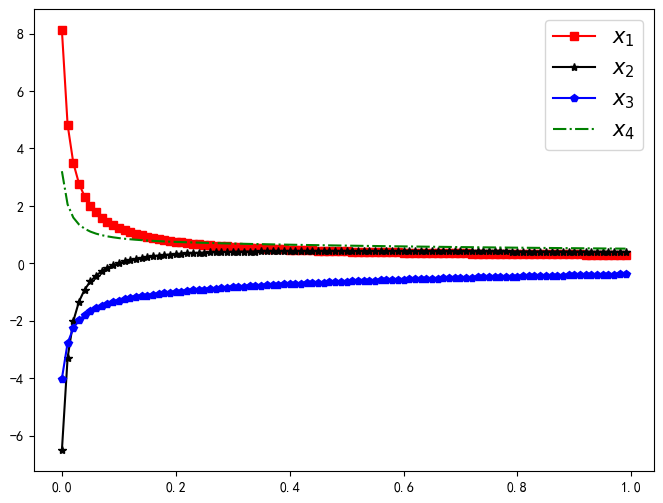

In [10]:
# 方法一：绘制岭迹线
# 列表b用于存储回归系数的空列表
b = []  
alpha = np.arange(0,1,0.01)
for a in alpha:
    # 创建岭回归模型，设置λ并训练
    md = Ridge(alpha = a).fit(x,y)
    # 将模型的回归系数放入b中
    b.append(md.coef_)

fig = plt.figure(figsize=(8,6))
# 线性图的线条样式
st=['s-r','*-k','p-b','g-.'] 
# 对于四个自变量，使用for循环
for i in range(4):
    # 绘制线性图，横坐标：λ值，纵坐标：β1，β2，β3，β4
    plt.plot(alpha,np.array(b)[:,i],st[i])
# 设置图例
plt.legend(['$x_1$','$x_2$','$x_3$','$x_4$'],fontsize=15)
# 显示图像
plt.show()

In [11]:
# 方法二：RidgeCV()函数
mdcv=RidgeCV(alphas=alpha[1:]).fit(x,y);
print("最优alpha=",mdcv.alpha_) 

最优alpha= 0.01


#### 4.2.3 创建岭回归模型

In [12]:
# 构建并拟合模型
model = Ridge(alpha=0.01).fit(x,y)  
# 提出标准化数据的回归系数β1,β2,β3
parma1 = model.coef_  
# 回归常数β0
parma0 = model.intercept_
print("标准化数据的所有回归系数为：",parma1)
print("标准化数据的回归常数为：",parma0)

标准化数据的所有回归系数为： [ 4.82672902 -3.29572067 -2.77932215  2.04911688]
标准化数据的回归常数为： 4.230713637036805e-16


#### 4.2.4 数据标准化回归方程还原

因为上面得到的是标准化数据的回归方程，我们可以设为：

$$y = β_0 + β_1 x_1 + β_2 x_2 + β_3 x_3 + β_4 x_4$$

而数据 $x_1, x_2, x_3, x_4, y$ 是经过标准化后的数据，设标准化前的数据为：

$$\hat{x}_1, \hat{x}_2, \hat{x}_3, \hat{x}_4, \hat{y}$$

设原数据的均值为：

$$ \overline{x}_1, \overline{x}_2, \overline{x}_3, \overline{x}_4, \overline{y} $$

方差为：

$$σ_{x_1}, σ_{x_2}, σ_{x_3}, σ_{x_4}, σ_{y}$$

那么对于得到的回归方程

$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3 + \beta_4 x_4$

还原成

$\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 \hat{x}_1 + \hat{\beta}_2 \hat{x}_2 + \hat{\beta}_3 \hat{x}_3 + \hat{\beta}_4 \hat{x}_4$

的回归常数和回归系数为：

-  $$\hat{β}_0 = β_0 σ_{y} + \overline{y} - σ_{y} \sum_{i=1}^{4} {\frac{β_i \overline{x}_i}{σ_{x_i}}} $$
-  $$\hat{β}_i = σ_{y} \frac{β_i}{σ_{x_i}} $$

In [13]:
# 计算所有指标的均值和标准差
mu = np.mean(df.values,axis=0)
s = np.std(df.values,axis=0,ddof=1)
# 分开特征向量和目标向量的均值和标准差
x_mu = mu[:4]
y_mu = mu[4]
x_s = s[:4]
y_s = s[4]
b0 = parma0*y_mu+y_mu-y_s*sum(parma1*x_mu/x_s)
b1 = y_s*parma1/x_s
print("原数据的所有回归系数为：\n",b1)
print("原数据的回归常数为：",b0)
print("拟合优度：",model.score(x,y))

原数据的所有回归系数为：
 [ 209.86436783 -452.20487977 -631.6555047   358.13644027]
原数据的回归常数为： 344855.972755682
拟合优度： 0.8080606444134331


所以得到岭回归的线性方程为：

$$y =344855+209x_1-452x_2-631x_3+358x_4 $$

### 4.3 LASSO 回归

#### 4.3.1 LASSO 回归原理

对于多元线性回归模型 $Y = Xβ + ε$，参数方程的解为：

$$\hat{β} = {(X^TX)^{-1}X^TY}$$

其中：

$$
Y =
\begin{bmatrix}
y_1 \\
y_2 \\
\vdots \\
y_n
\end{bmatrix}, \quad
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \ldots & x_{1p} \\
1 & x_{21} & x_{22} & \ldots & x_{2p} \\
\vdots & \vdots & \vdots &   & \vdots \\
1 & x_{n1} & x_{n2} & \ldots & x_{np}
\end{bmatrix}, \quad
β =
\begin{bmatrix}
β_0 \\
β_1 \\
\vdots \\
β_p
\end{bmatrix}, \quad
ε =
\begin{bmatrix}
ε_1 \\
ε_2 \\
\vdots \\
ε_n
\end{bmatrix}

$$

多元线性回归模型的目标函数：

$$J(β) = \sum{{(Y-Xβ)}^2}$$

LASSO回归模型在目标函数上加了一个L1范数的惩罚项

$$J(β) = \sum{{(Y-Xβ)}^2}+λ{||β||}_1 = \sum{{(Y-Xβ)}^2}+\sum{λ|β|} = ESS(β)+λl_1(β)$$

其中:
- $ESS(β)$表示误差平方和
- $λl_1(β)$表示惩罚项

由于惩罚项是关于回归系数$β$的绝对值之和，因此惩罚项在零点处时不可导的，那么最小二乘法在此失效，故采用坐标下降法。

**岭回归与Lasso回归最大的区别在于岭回归引入的是L2范数惩罚项，Lasso回归引入的是L1范数惩罚项。**

随着正则化强度的增大，$β$的取值会逐渐变小，L1正则化会将参数压缩到0，L2正则化只会让参数尽量小，不会取到0。 所以在L1正则化在逐渐加强的过程中，相对不重要的特征的参数会比相对重要的特征的参数更快地变成0。 所以L1正则化本质是一个特征选择的过程。选出少量但重要的特征，以防止过拟合问题。而L2正则化在加强的过程中，会尽量让每个特征对模型都有一些贡献，相对不重要的特征的参数会非常接近0。

#### 4.3.2 导入数据

In [14]:
df = pd.read_csv("../data/regularization.csv")
df = df[['酱油','蚝油','酱类','其他','营业收入']]
# 数据标准化
sc = StandardScaler()
data = sc.fit_transform(df)
# 提出自变量和因变量数据
x=data[:,:4]
y=data[:,4]  

#### 4.3.3 确定$λ$值

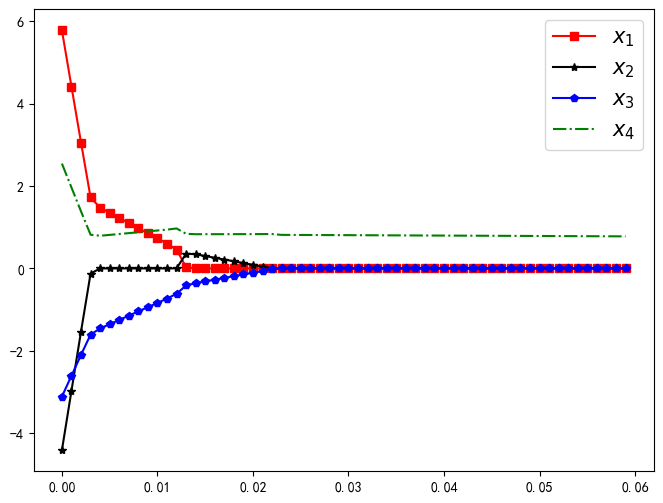

In [15]:
b = []  
alpha = np.arange(0,0.06,0.001)
for a in alpha:
    # 创建Lasso回归模型，设置λ并训练
    md = Lasso(alpha = a).fit(x,y)
    # 将模型的回归系数放入b中
    b.append(md.coef_)

fig = plt.figure(figsize=(8,6))
# 线性图的线条样式
st=['s-r','*-k','p-b','g-.'] 
# 对于四个自变量，使用for循环
for i in range(4):
    # 绘制线性图，横坐标：λ值，纵坐标：β1，β2，β3，β4
    plt.plot(alpha,np.array(b)[:,i],st[i])
# 设置图例
plt.legend(['$x_1$','$x_2$','$x_3$','$x_4$'],fontsize=15)
# 显示图像
plt.show()

In [16]:
# 方法二：RidgeCV()函数
mdcv=LassoCV(alphas=alpha[1:]).fit(x,y);
print("最优alpha=",mdcv.alpha_) 

最优alpha= 0.041


#### 4.3.4 构建 Lasso 模型

In [17]:
# 构建并拟合模型
model = Lasso(alpha=0.02).fit(x,y)  
# 提出标准化数据的回归系数β1,β2,β3
parma1 = model.coef_  
# 回归常数β0
parma0 = model.intercept_
print("标准化数据的所有回归系数为：",parma1)
print("标准化数据的回归常数为：",parma0)

标准化数据的所有回归系数为： [ 0.          0.08645823 -0.10471548  0.83225618]
标准化数据的回归常数为： 1.347591584549112e-16


#### 4.3.5 数据标准化回归方程还原

In [18]:
def trans_coef(df,parma0,parma1):
    '''
    df：原数据（未标准化）
    parma0：标准化数据得到的回归常数
    parma1：标准化数据得到的回归系数
    '''
    # 计算所有指标的均值和标准差
    mu = np.mean(df.values,axis=0)
    s = np.std(df.values,axis=0,ddof=1)
    # 分开特征向量和目标向量的均值和标准差
    x_mu = mu[:4]
    y_mu = mu[4]
    x_s = s[:4]
    y_s = s[4]
    b0 = parma0*y_mu+y_mu-y_s*sum(parma1*x_mu/x_s)
    b1 = y_s*parma1/x_s
    return b0,b1
b0,b1 = trans_coef(df,parma0,parma1)
print("原数据的所有回归系数为：\n",b1)
print("原数据的回归常数为：",b0)
print("拟合优度：",model.score(x,y))

原数据的所有回归系数为：
 [  0.          11.86290886 -23.79864825 145.45840181]
原数据的回归常数为： 306126.4909836769
拟合优度： 0.7082770144139456


所以得到Lasso回归的线性方程为：

$$y =306126+11x_2-23x_3+145x_4 $$


## 5. 小结

本次实验介绍了线性模型的两种正则化模型：岭回归和LASSO回归。实现了基于Python实现岭回归和LASSO回归的模型的参数估计和数据标准化回归方程还原。

通过本次实验需要掌握以下内容：
- 掌握岭回归的思路和基本方法
- 掌握LASSO回归的思路和基本方法
